In [7]:
import numba
import numpy as np
from profdata import load_profdata
import matplotlib.pyplot as plt

In [8]:
@numba.jit(nopython=True, boundscheck=False)
def sim_matrix_impl(act_hash, res):
    N, K = act_hash.shape
    for i in range(N):
        for j in range(N):
            res[i, j] = (act_hash[i] == act_hash[j]).sum()

def sim_matrix(act_hash):
    N, K = act_hash.shape
    res = np.empty((N, N), dtype=np.uint8)
    sim_matrix_impl(act_hash, res)
    return res

In [9]:
data = load_profdata('pgo-data/boom_m_1.T1.prof.bin')

In [11]:
act_hash = data.threads[0].act_hash
iou = sim_matrix(act_hash) / 32

In [6]:
np.save('prof-method-stat/minhash-method.npy', iou)

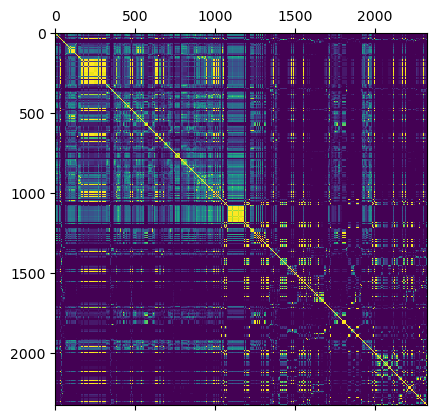

In [5]:
plt.matshow(iou, cmap='viridis')
plt.savefig('minhash.png')